# Comparing two Bayesian models

## Introduction 

This continues on from the last post, where we had some data with outliers, and we used a Normal distribution, and a Fat-Tailed Student T distribution, to create two models for the data.  Here, we will examine the two models in more detail

## Implementation

### Imports

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import preliz as pz
import pymc as pm
import pytensor

### Load our observed data

In [2]:
data_url = "data/chemical_shifts.csv"
observed = pd.read_csv(data_url)

### Configure PyTensor

Don't build C programs to compile (small models shouldn't need it, and I have a glitch in my environment, with incompatible C libraries / compilers that I can't be bothered to resolve :) 

In [3]:
pytensor.config.cxx = ""

### Build model

See previous posts for a detailed description

In [4]:
with pm.Model() as shift_model:
    mu = pm.Uniform("mu", lower=40, upper=60)
    sigma = pm.HalfNormal("sigma", sigma=5)
    Y = pm.Normal("Y", mu=mu, sigma=sigma, observed=observed)
    idata = pm.sample(idata_kwargs={"log_likelihood": True})

NUTS[nutpie]: [mu, sigma]


Output()

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\pymc\sampling\mcmc.py:1010: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_external_nuts(


Check the diagnostics (all good)

In [5]:
problems = az.diagnose(idata)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


Check the summary statistics

In [6]:
az.summary(idata, kind="stats", ci_kind="hdi")

,mean,sd,hdi89_lb,hdi89_ub
mu,54,0.53,53,54
sigma,3.6,0.39,2.9,4.1


Check the model diagram (all good)

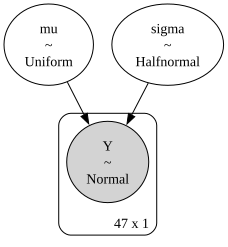

In [7]:
pm.model_to_graphviz(shift_model)

Enhance our model datastructure to allow more plots

In [8]:
with shift_model:
    pm.sample_posterior_predictive(idata, extend_inferencedata=True)
# end with

Sampling: [Y]


Output()

Compare the distribution of predicted KDE, against a KDE from the actual data

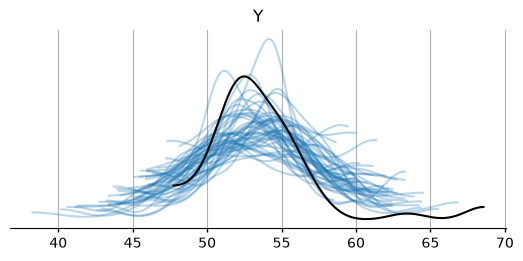

In [9]:
with shift_model:
    pc = az.plot_ppc_dist(
        idata,
        kind="kde",
    )
# end with

pc.viz["figure"].item().get_axes()[0].grid(True, axis="both")

----------------------------

## Using Fat Tail distribution

Now repeat the process with a Student T distribution

In [10]:
with pm.Model() as shift_model_t:
    mu = pm.Uniform("mu", lower=40, upper=60)
    sigma = pm.HalfNormal("sigma", sigma=5)
    nu = pm.Exponential("nu", 1 / 30)
    Y = pm.StudentT("Y", mu=mu, sigma=sigma, nu=nu, observed=observed)
    idata_t = pm.sample(idata_kwargs={"log_likelihood": True})

# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [mu, sigma, nu]


Output()

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\pymc\sampling\mcmc.py:1010: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_external_nuts(


In [11]:
problems = az.diagnose(idata_t)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


In [12]:
az.summary(idata_t, kind="stats", ci_kind="hdi")

,mean,sd,hdi89_lb,hdi89_ub
mu,53,0.39,52,54
sigma,2.2,0.39,1.6,2.8
nu,4.4,3,1.4,7.3


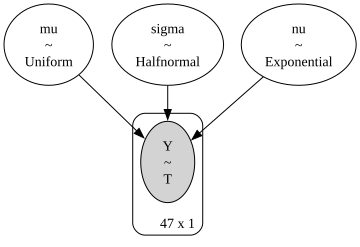

In [13]:
pm.model_to_graphviz(shift_model_t)

In [14]:
with shift_model_t:
    pm.sample_posterior_predictive(idata_t, extend_inferencedata=True)
# end with

Sampling: [Y]


Output()

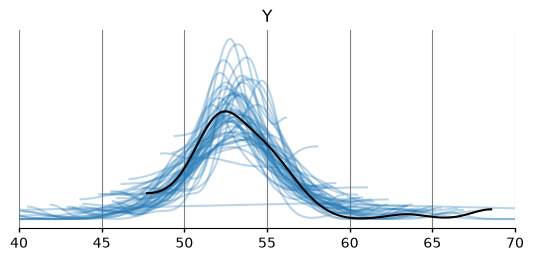

In [15]:
with shift_model_t:
    pc_t = az.plot_ppc_dist(
        idata_t,
        kind="kde",
    )
    pc_t.map(az.visuals.set_xlim, limits=(40, 70))
    pc_t.map(az.visuals.grid, axis="x", color="gray")
# end with

Compare with the Normal model KDE predictions below

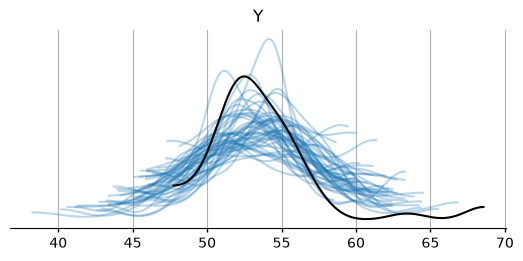

In [16]:
pc.viz["figure"].item()

-------------------------------

### Compare model predictions

#### Compare prediction of median statistic 

Student T model is better

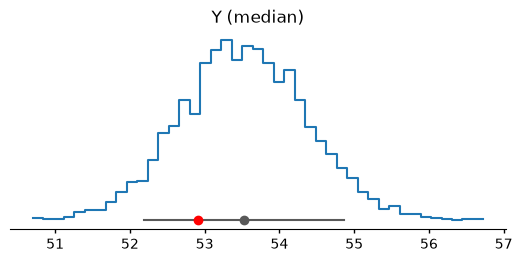

In [17]:
az.plot_ppc_tstat(
    idata,
    kind="hist",
    t_stat="median",
    visuals={
        "dist": True,
        "credible_interval": {},
        "point_estimate": {},
        "observed_tstat": {"color": "red"},
    },
)

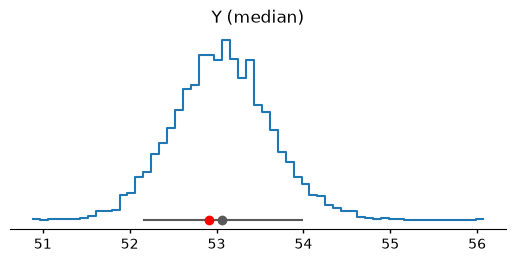

In [18]:
az.plot_ppc_tstat(
    idata_t,
    kind="hist",
    t_stat="median",
    visuals={
        "dist": True,
        "credible_interval": {},
        "point_estimate": {},
        "observed_tstat": {"color": "red"},
    },
)

----------------------

### DGOF plots

DGOF stands for _Distributional Goodness-of-Fit_

Quoting:

    A Δ-ECDF-PIT diagnostic is plotted to assess the goodness-of-fit of the estimated distributions to the underlying data

In both the Normal model, and the Student T model, for _mu_ and _sigma_, we can't reject the null hypothesis (e.g. for Normal _mu_ prediction, the observed line would be observed 41% of the time)

In the plots below, PIT stands for _Probability Integral Transform_: "a statistical method used for posterior predictive checks to see how well a model fits observed data"

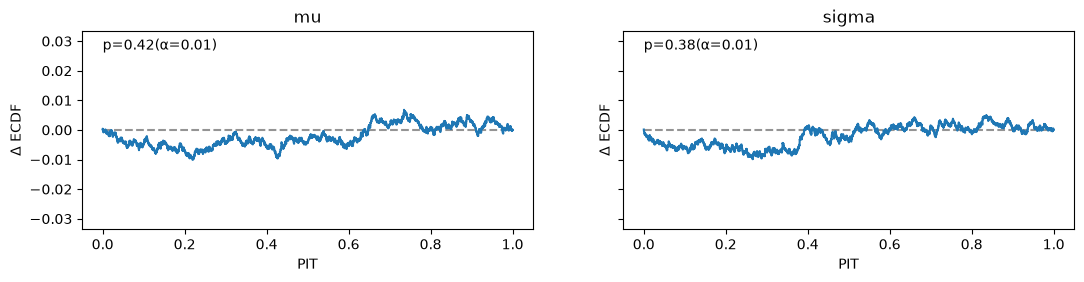

In [19]:
az.plot_dgof(idata)

For the Student T model, the _nu_ (or Fat-Tailed-ness of the distribution) appears to indicate problems with the model sampling.  The points that contribute the most to deviations from uniformity are highlighted in orange

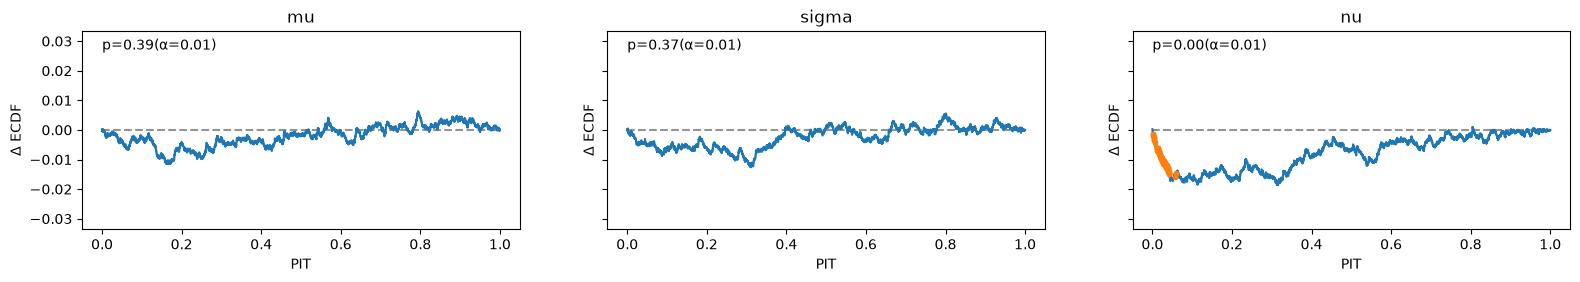

In [20]:
az.plot_dgof(idata_t)

--------------------
### A DGOF plot with KDE for variables

#### Normal model

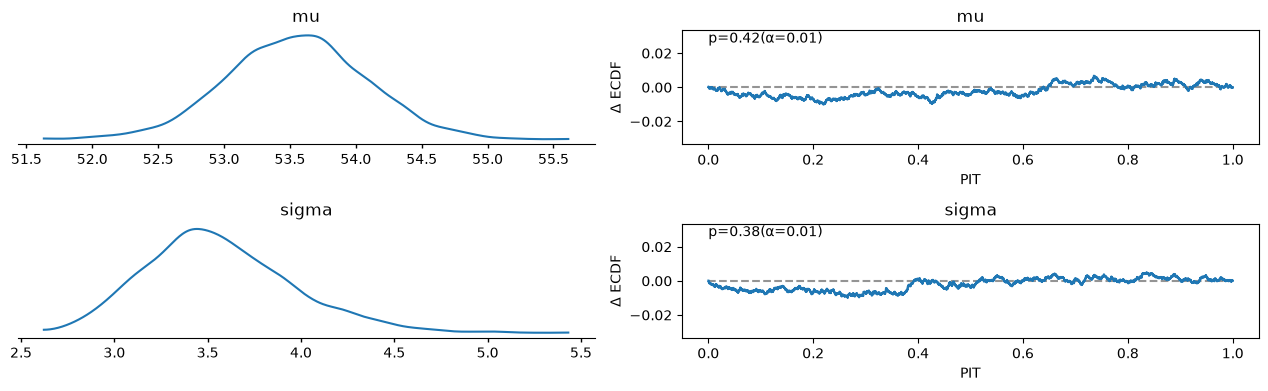

In [21]:
az.plot_dgof_dist(idata)
plt.tight_layout() # Safeguards against overlapping labels/axes titles
plt.show()

#### Student T model

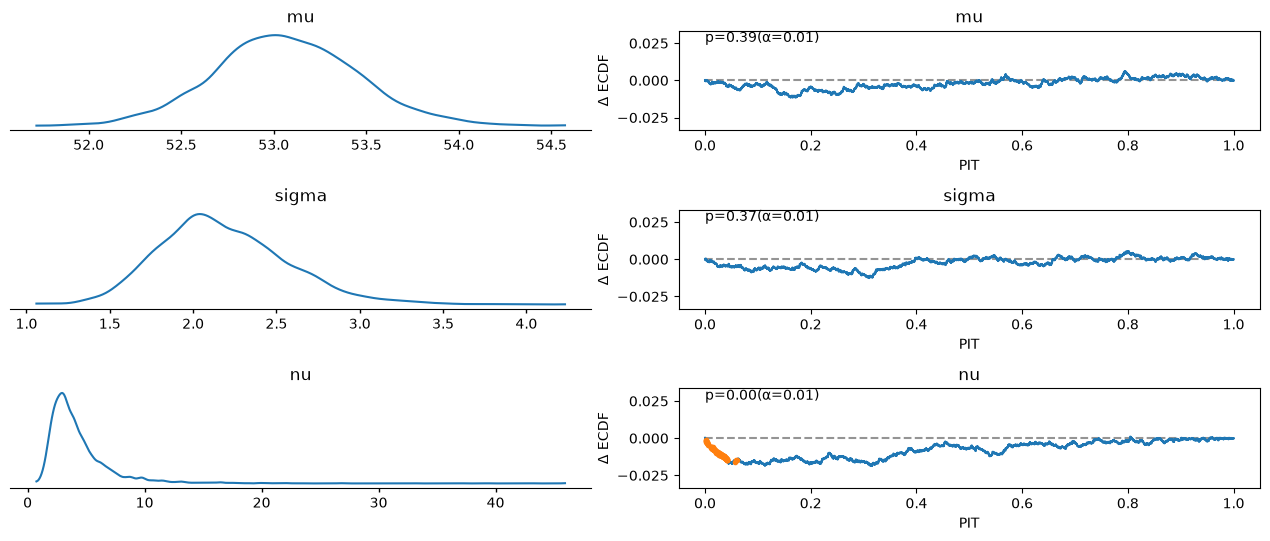

In [22]:
az.plot_dgof_dist(idata_t)
plt.tight_layout() # Safeguards against overlapping labels/axes titles
plt.show()

--------------------
### Rank sampling

To look at the model execution, we examine the different chains (effectively multi=processor threads), so see if all chains had equal contribution to the model.  If not (we get an unlikely P value), it may indicate sampling problems in the model execution

For the Normal model, it appears all chains are OK

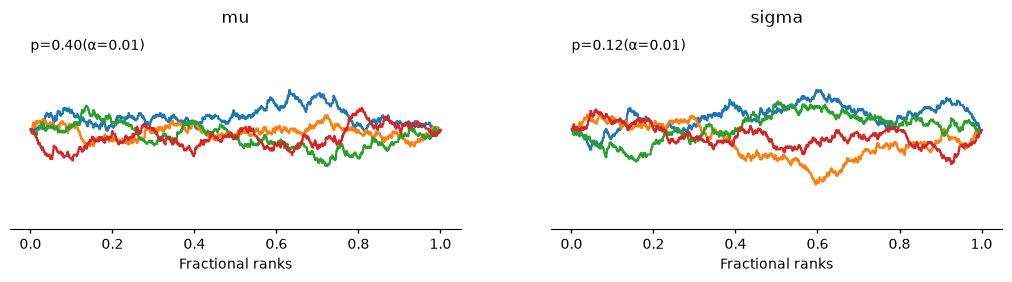

In [23]:
az.plot_rank(idata)

For the Student T model, we can't reject the null hypothesis that all chains contribute equally, but the _sigma_ has highlighted area of concern

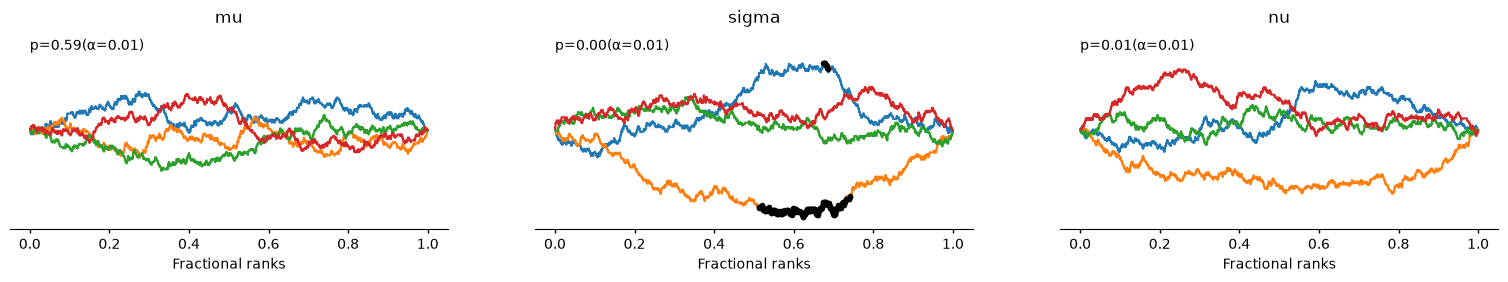

In [24]:
az.plot_rank(idata_t)

--------------------

### Explicit model comparison

We use the ArViz _plot_compare()_ function.  This indicatres the Student T model is the best of the two.

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\arviz_stats\loo\loo_helper.py:1170: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\arviz_stats\loo\loo_helper.py:1170: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


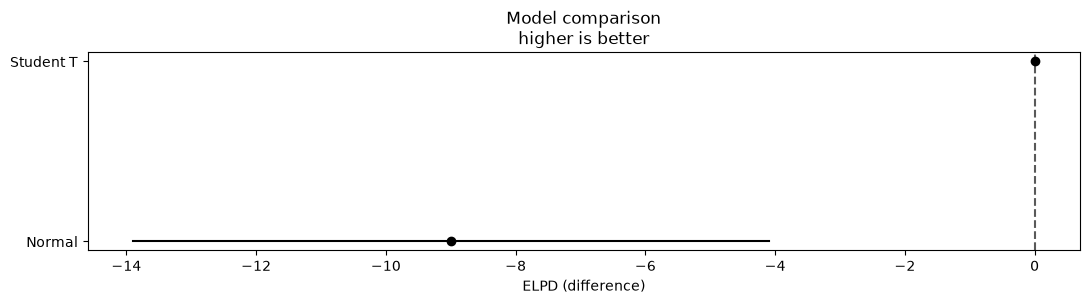

In [25]:
mc = az.compare({"Normal": idata, "Student T": idata_t})

az.plot_compare(mc)

I should respond to the ArViz warnings by:
- Using different, more robust priors
- Inspecting influential points


---------------------------

### expected log pointwise predictive density (ELPD)

The output shows that the Student T model is ranked highest at predicting data points, with a very probability.

For this exercise I am ignoring these warnings

In [26]:
az.compare({"Normal": idata, "Student T": idata_t})

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\arviz_stats\loo\loo_helper.py:1170: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\arviz_stats\loo\loo_helper.py:1170: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Student T,0,0.0,0.0,NaN,,1 k̂ > 0.70,3.7,-120.0,9.0,1.0
Normal,1,-9.0,4.9,0.97,N < 100,1 k̂ > 0.70,5.5,-130.0,12.0,0.0


    If  the value  "N < 100" (small data), is shown, the ELPD differences and probabilities (worse or better) should be interpreted with caution as the error distribution is skewed or thick tailed and the normal approximation not well calibrated.

### empirical cumulative distribution function (ECDF)

We look at how well the models predict the Cumulative Distribution Function.  A flat line is best

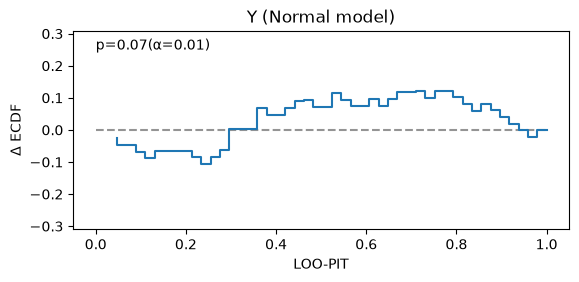

In [29]:
az.plot_loo_pit(
    idata,
    visuals={"title": {"text": "Normal model"}},
)

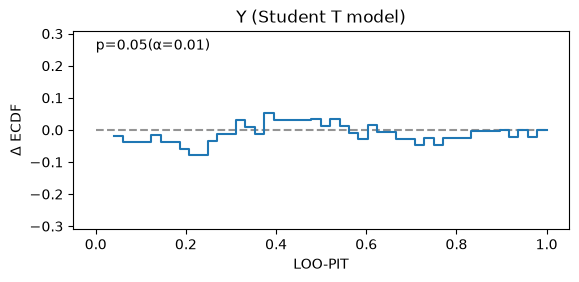

In [30]:
az.plot_loo_pit(
    idata_t,
    visuals={"title": {"text": "Student T model"}},
)

------------------------------------

## Conclusions

To my in-expert eye, it appears that the Student T model is a better model, although there were indications of problems in model execution.  Of course, this assumes that the outlier points are really valid, and should be included in our model.

--------------

## Reproducability

In [31]:
%load_ext watermark

In [32]:
%watermark

Last updated: 2026-09-22T17:46:31.760054+10:00

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

Compiler    : MSC v.1944 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 170 Stepping 4, GenuineIntel
CPU cores   : 22
Architecture: 64bit



In [33]:
%watermark -h -iv -co

conda environment: bayes_env

Hostname: INSPIRON16

arviz     : 1.3.0
matplotlib: 3.11.1
numpy     : 2.4.6
pandas    : 3.0.5
preliz    : 0.28.0
pymc      : 6.3.1
pytensor  : 3.3.0

